# ДЗ: эмбеддинги (Word2Vec / MiniLM) и TF-IDF
1. Воспроизведение ноутбука с занятия (с исправлениями)
2. Материалы прошлого ДЗ в виде разных векторов: TF-IDF vs CBOW (и MiniLM)
3. Векторные операции над разными эмбеддингами, можно ли с TF-IDF
4. MiniLM-L12-v2 vs word2vec-google-news-300: одинаково ли они работают на операциях с предложениями
5. Стемминг для обеих моделей на английских текстах

In [1]:
import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import gensim.downloader as api
from gensim.models import KeyedVectors
from sentence_transformers import SentenceTransformer, util

pd.set_option("display.width", 180)
np.set_printoptions(precision=3, suppress=True)

## 1. Ноутбук с занятия

In [2]:
# Word2Vec (Google News, 300d). Локально можно указать путь к файлу через W2V_PATH, иначе скачается через gensim
W2V_PATH = os.environ.get("W2V_PATH")
t = time.time()
if W2V_PATH:
    word_vectors = KeyedVectors.load_word2vec_format(W2V_PATH, binary=True, limit=1_000_000)
else:
    word_vectors = api.load("word2vec-google-news-300")
print(f"Word2Vec загружен за {time.time()-t:.0f} с: слов {len(word_vectors.key_to_index):,}, размерность {word_vectors.vector_size}")

Word2Vec загружен за 20 с: слов 1,000,000, размерность 300


In [3]:
context_words = ["space", "rocket", "robot", "star"]
print("Контекст:", context_words)
for w, s in word_vectors.most_similar(positive=context_words, topn=3):
    print(f"  {w}: {s:.3f}")

print("\nking - man + woman:")
for w, s in word_vectors.most_similar(positive=["king", "woman"], negative=["man"], topn=3):
    print(f"  {w}: {s:.3f}")

Контекст: ['space', 'rocket', 'robot', 'star']


  spaceship: 0.625
  spacecraft: 0.575
  robotic_spacecraft: 0.566

king - man + woman:
  queen: 0.712
  monarch: 0.619
  princess: 0.590


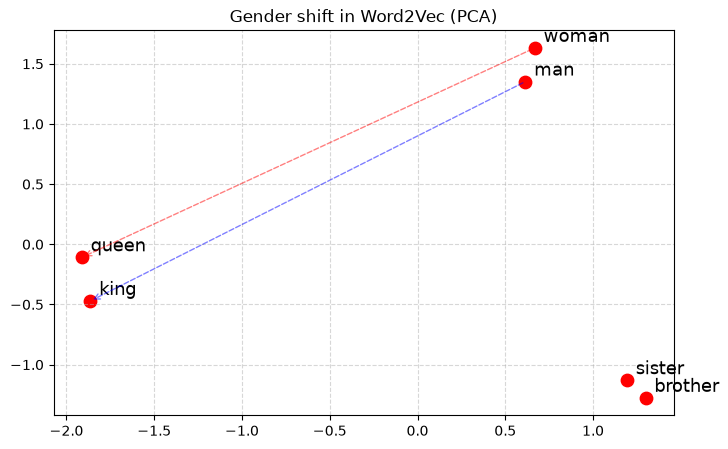

In [4]:
words_to_plot = ["king", "man", "queen", "woman", "brother", "sister"]
vecs2d = PCA(n_components=2).fit_transform(np.array([word_vectors[w] for w in words_to_plot]))
plt.figure(figsize=(8, 5))
plt.scatter(vecs2d[:, 0], vecs2d[:, 1], color="red", s=80)
for i, w in enumerate(words_to_plot):
    plt.annotate(w, (vecs2d[i, 0] + .05, vecs2d[i, 1] + .05), fontsize=13)
for a, b, c in [(1, 0, "blue"), (3, 2, "red")]:   # man->king, woman->queen
    plt.annotate("", xy=vecs2d[b], xytext=vecs2d[a], arrowprops=dict(arrowstyle="->", color=c, alpha=.5, ls="--"))
plt.title("Gender shift in Word2Vec (PCA)"); plt.grid(ls="--", alpha=.5); plt.show()

In [5]:
# Многоязычная MiniLM из занятия
ml_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
phrases = ["я люблю спелые яблоки", "I love ripe apples", "как починить кухонный стол"]
emb = ml_model.encode(phrases)
print(f"'я люблю спелые яблоки' vs 'I love ripe apples':        {util.cos_sim(emb[0], emb[1]).item():.3f}")
print(f"'я люблю спелые яблоки' vs 'как починить кухонный стол': {util.cos_sim(emb[0], emb[2]).item():.3f}")

'я люблю спелые яблоки' vs 'I love ripe apples':        0.960
'я люблю спелые яблоки' vs 'как починить кухонный стол': 0.000


In [6]:
# Арифметика над векторами предложений (пляж - солнце + сноуборд)
v_beach, v_sun, v_ski = ml_model.encode(["солнечный песчаный пляж у океана", "жаркое солнце тепло лето", "зимний горнолыжный курорт сноуборд"])
cands = ["отпуск на горнолыжной базе в Альпах зимой", "жарить шашлыки на даче под Гомелем",
         "экскурсия по музеям Варшавы", "поездка на Мальдивы в пятизвездочный отель"]
scores = util.cos_sim(v_beach - v_sun + v_ski, ml_model.encode(cands)).flatten()
for s, c in sorted(zip(scores.tolist(), cands), reverse=True):
    print(f"[{s:.2f}] {c}")

[0.56] отпуск на горнолыжной базе в Альпах зимой
[0.21] поездка на Мальдивы в пятизвездочный отель
[0.15] экскурсия по музеям Варшавы
[0.09] жарить шашлыки на даче под Гомелем


In [7]:
# FAISS. Исправления по сравнению с исходным ноутбуком:
#  1) векторы нормируем (иначе inner product != косинус, были «скоры» 14.077)
#  2) для 5 документов IVF не нужен (кластеризация 5 точек в 2 центроида даёт предупреждение), берём точный Flat-индекс
#  3) nprobe в исходнике задавался переменной, но не применялся к индексу
import faiss
kb = ["Как испечь домашнюю пиццу Маргарита", "Разработка веб-приложений на Python и FastAPI",
      "Итальянское тесто для лепешек с сыром", "Настройка контейнеров Docker в продакшене",
      "Классические итальянские рецепты с пастой и томатами"]
db = ml_model.encode(kb).astype("float32"); faiss.normalize_L2(db)
index = faiss.IndexFlatIP(db.shape[1]); index.add(db)
q = ml_model.encode(["хочу приготовить лепешку с сыром"]).astype("float32"); faiss.normalize_L2(q)
sc, ix = index.search(q, 4)
for s, i in zip(sc[0], ix[0]):
    print(f"[{s:.3f}] {kb[i]}")

# IVF имеет смысл на больших объёмах: проверим на 20 000 случайных векторов, nprobe реально применяется
rng = np.random.default_rng(0)
big = rng.normal(size=(20000, 384)).astype("float32"); faiss.normalize_L2(big)
quant = faiss.IndexFlatIP(384)
ivf = faiss.IndexIVFFlat(quant, 384, 64, faiss.METRIC_INNER_PRODUCT); ivf.train(big); ivf.add(big)
exact = faiss.IndexFlatIP(384); exact.add(big)
qq = big[:200] + 0.3 * rng.normal(size=(200, 384)).astype("float32"); faiss.normalize_L2(qq)
_, true_ix = exact.search(qq, 1)
for nprobe in (1, 4, 16):
    ivf.nprobe = nprobe
    _, got = ivf.search(qq, 1)
    print(f"IVF nprobe={nprobe:>2}: recall@1 = {(got == true_ix).mean():.2f}")

[0.827] Итальянское тесто для лепешек с сыром
[0.643] Как испечь домашнюю пиццу Маргарита
[0.557] Классические итальянские рецепты с пастой и томатами
[0.199] Настройка контейнеров Docker в продакшене


IVF nprobe= 1: recall@1 = 0.06
IVF nprobe= 4: recall@1 = 0.19
IVF nprobe=16: recall@1 = 0.51


## 2. Материалы прошлого ДЗ в виде разных векторов: TF-IDF vs CBOW (и MiniLM)

In [8]:
en_model = SentenceTransformer("sentence-transformers/all-MiniLM-L12-v2")
docs_hw = [
    "The history of artificial intelligence began in the mid-20th century with the theoretical works of Alan Turing and the creation of the first expert systems. However, a real breakthrough occurred with the development of machine learning and the transition to deep neural networks. Modern algorithms require enormous computational power and colossal amounts of labeled data for training.",
    "The progress of AI is particularly noticeable in the fields of biology and medicine. Algorithms have learned to analyze medical images with accuracy exceeding human capabilities and to predict the spatial structure of proteins. This has drastically accelerated the process of developing new drugs and making diagnoses.",
    "Despite the benefits, the implementation of these technologies carries serious risks. Automation leads to the disappearance of entire professions, and bias in training datasets can lead to discrimination. Furthermore, the problem of goal alignment and the hypothetical creation of superintelligence require the establishment of strict international laws and ethical committees.",
]
tf = TfidfVectorizer(); Xtf = tf.fit_transform(docs_hw)
word = "learning"
v_tfidf = Xtf[:, tf.vocabulary_[word]].toarray().ravel()
v_cbow = word_vectors[word]
v_minilm = en_model.encode(word)
summary = pd.DataFrame({
    "размерность": [len(v_tfidf), len(v_cbow), len(v_minilm)],
    "ненулевых": [int((v_tfidf != 0).sum()), int((v_cbow != 0).sum()), int((v_minilm != 0).sum())],
    "норма": [np.linalg.norm(v_tfidf), np.linalg.norm(v_cbow), np.linalg.norm(v_minilm)],
    "мин": [v_tfidf.min(), v_cbow.min(), v_minilm.min()],
}, index=["TF-IDF", "Word2Vec (CBOW)", "MiniLM-L12-v2"]).round(3)
print(f"Слово «{word}»"); print("TF-IDF вектор:", v_tfidf); print("CBOW, первые 6 компонент:", v_cbow[:6])
summary

Слово «learning»
TF-IDF вектор: [0.121 0.    0.   ]
CBOW, первые 6 компонент: [-0.088  0.148 -0.063  0.118  0.11   0.043]


,размерность,ненулевых,норма,мин
TF-IDF,3,1,0.121,0.000
Word2Vec (CBOW),300,300,2.501,-0.377
MiniLM-L12-v2,384,384,1.000,-0.150


In [9]:
# 1) TF-IDF-вектор слова зависит от корпуса: добавим документы, и координаты слова «learning» поменяются целиком
more = docs_hw + ["Italian pizza recipe with cheese and tomatoes", "Machine learning and deep learning are popular topics"]
tf2 = TfidfVectorizer(); X2 = tf2.fit_transform(more)
print("TF-IDF «learning», 3 документа:", Xtf[:, tf.vocabulary_[word]].toarray().ravel())
print("TF-IDF «learning», 5 документов:", X2[:, tf2.vocabulary_[word]].toarray().ravel())
print("CBOW «learning» не зависит от корпуса, первые 3 числа:", word_vectors[word][:3])

# 2) Близость слов
pairs = [("learning", "training"), ("doctor", "physician"), ("algorithms", "medicine"), ("learning", "pizza")]
rows = []
for a, b in pairs:
    r = {"пара": f"{a} / {b}"}
    r["TF-IDF"] = (cosine_similarity(X2[:, tf2.vocabulary_[a]].toarray().T, X2[:, tf2.vocabulary_[b]].toarray().T)[0, 0]
                   if a in tf2.vocabulary_ and b in tf2.vocabulary_ else np.nan)
    r["CBOW"] = float(word_vectors.similarity(a, b))
    r["MiniLM"] = float(util.cos_sim(en_model.encode(a), en_model.encode(b)))
    rows.append(r)
pd.DataFrame(rows).set_index("пара").round(3)

TF-IDF «learning», 3 документа: [0.121 0.    0.   ]
TF-IDF «learning», 5 документов: [0.094 0.    0.    0.    0.604]
CBOW «learning» не зависит от корпуса, первые 3 числа: [-0.088  0.148 -0.063]


,TF-IDF,CBOW,MiniLM
пара,,,
learning / training,0.105,0.438,0.665
doctor / physician,NaN,0.781,0.848
algorithms / medicine,0.769,0.044,0.272
learning / pizza,0.000,0.101,0.225


*(nan = слова нет в словаре TF-IDF, т.к. не встречается в корпусе — ещё одно отличие: у TF-IDF нет вектора для слов вне корпуса.)*

## 3. Векторные операции над разными эмбеддингами. Можно ли их выполнять с TF-IDF?

In [10]:
from gensim.test.utils import datapath
# Тест на аналогии a:b :: c:? из стандартного набора Google (questions-words.txt)
cats = {"capital-common-countries", "family", "gram3-comparative", "gram6-nationality-adjective"}
quads, cur = [], None
for line in open(datapath("questions-words.txt"), encoding="utf8"):
    if line.startswith(":"): cur = line[1:].strip(); continue
    if cur in cats: quads.append((cur, *line.lower().split()))
print("Всего вопросов в выбранных категориях:", len(quads))

# Корпус для TF-IDF: английские новости (CNN/DailyMail, validation). Нужен словарь пошире, чем 3 документа
CNN = os.environ.get("CNN_PATH", "data/cnn_val.parquet")
if os.path.exists(CNN):
    cnn = pd.read_parquet(CNN)
else:                                                     # скачивается один раз (35 МБ)
    import urllib.request; os.makedirs(os.path.dirname(CNN) or ".", exist_ok=True)
    urllib.request.urlretrieve("https://huggingface.co/datasets/abisee/cnn_dailymail/resolve/main/3.0.0/validation-00000-of-00001.parquet", CNN)
    cnn = pd.read_parquet(CNN)
print("Статей:", len(cnn), "| колонки:", list(cnn.columns))
WORD = re.compile(r"[A-Za-z]+")
tok_en = lambda s: WORD.findall(s.lower())
cnn_docs = [" ".join(tok_en(a)[:400]) for a in cnn["article"][:4000]]

Всего вопросов в выбранных категориях: 3943


Статей: 13368 | колонки: ['article', 'highlights', 'id']


In [11]:
tf_big = TfidfVectorizer(min_df=3)
Xbig = tf_big.fit_transform(cnn_docs)                    # документы x термины
Wtf = Xbig.T.tocsr()                                     # вектор слова = его столбец (профиль по 4000 документам)
print("TF-IDF: словарь", len(tf_big.vocabulary_), "терминов, размерность вектора слова =", Wtf.shape[1])

# Общий словарь кандидатов: слова вопросов, которые есть во всех трёх моделях
words_all = {w for q in quads for w in q[1:]}
vocab = sorted(w for w in words_all if w in word_vectors.key_to_index and w in tf_big.vocabulary_)
qs = [q for q in quads if all(w in vocab for w in q[1:])]
print(f"Слов в общем словаре: {len(vocab)}, вопросов, где все 4 слова есть везде: {len(qs)}")

def l2(M):
    M = np.asarray(M, dtype="float32"); return M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-9)
E = {
    "TF-IDF (профиль слова по документам)": l2(np.vstack([Wtf[tf_big.vocabulary_[w]].toarray() for w in vocab])),
    "Word2Vec (CBOW)": l2(np.vstack([word_vectors[w] for w in vocab])),
    "MiniLM-L12-v2 (слово как текст)": l2(en_model.encode(vocab, batch_size=128)),
}
idx = {w: i for i, w in enumerate(vocab)}
rows = []
for name, M in E.items():
    ok, per = 0, defaultdict(list)
    for cat, a, b, c, d in qs:
        target = M[idx[b]] - M[idx[a]] + M[idx[c]]
        sims = M @ (target / np.linalg.norm(target))
        sims[[idx[a], idx[b], idx[c]]] = -9
        hit = vocab[int(sims.argmax())] == d
        ok += hit; per[cat].append(hit)
    rows.append({"модель": name, "accuracy": ok / len(qs), **{k: np.mean(v) for k, v in per.items()}})
res_analogy = pd.DataFrame(rows).set_index("модель").round(3)
res_analogy

TF-IDF: словарь 17267 терминов, размерность вектора слова = 4000
Слов в общем словаре: 177, вопросов, где все 4 слова есть везде: 1859


,accuracy,capital-common-countries,family,gram3-comparative,gram6-nationality-adjective
модель,,,,,
TF-IDF (профиль слова по документам),0.271,0.511,0.146,0.019,0.750
Word2Vec (CBOW),0.797,0.611,0.942,0.934,0.508
MiniLM-L12-v2 (слово как текст),0.907,0.944,0.738,0.903,0.985


In [12]:
# Операции над векторами предложений (английская MiniLM): «пляж − солнце + лыжи»
v = lambda s: en_model.encode(s)
mystery = v("sandy beach by the ocean") - v("hot summer sun") + v("winter ski resort snowboard")
cands = ["a vacation at an alpine ski base in winter", "grilling barbecue at a country house",
         "a guided tour of museums in Warsaw", "a trip to a five-star hotel in the Maldives"]
print("MiniLM, sentence arithmetic:")
for s, c in sorted(zip(util.cos_sim(mystery, en_model.encode(cands)).flatten().tolist(), cands), reverse=True):
    print(f"  [{s:.2f}] {c}")

# То же над TF-IDF-векторами предложений
tfs = TfidfVectorizer().fit(cands + ["sandy beach by the ocean", "hot summer sun", "winter ski resort snowboard"])
m_tf = (tfs.transform(["sandy beach by the ocean"]) - tfs.transform(["hot summer sun"]) + tfs.transform(["winter ski resort snowboard"])).toarray()
print("\nTF-IDF, sentence arithmetic:")
for s, c in sorted(zip(cosine_similarity(m_tf, tfs.transform(cands)).ravel().tolist(), cands), reverse=True):
    print(f"  [{s:.2f}] {c}")
print("\nОтрицательные координаты в результате TF-IDF-арифметики:", int((m_tf < 0).sum()), "из", m_tf.size)

MiniLM, sentence arithmetic:
  [0.32] a vacation at an alpine ski base in winter
  [0.19] a trip to a five-star hotel in the Maldives
  [0.15] a guided tour of museums in Warsaw
  [0.08] grilling barbecue at a country house

TF-IDF, sentence arithmetic:
  [0.17] a vacation at an alpine ski base in winter
  [0.07] a trip to a five-star hotel in the Maldives
  [0.00] grilling barbecue at a country house
  [0.00] a guided tour of museums in Warsaw

Отрицательные координаты в результате TF-IDF-арифметики: 3 из 33


## 4. MiniLM-L12-v2 vs word2vec-google-news-300: предложения

In [13]:
# Мини-бенчмарк: пары предложений с оценкой сходства 0..5 (оценки расставлены вручную автором ДЗ)
pairs = [
 ("A man is playing a guitar.", "A person plays an instrument.", 4.5),
 ("A woman is slicing an onion.", "Someone is cutting a vegetable.", 4.0),
 ("The cat sat on the mat.", "A kitten is resting on a rug.", 4.0),
 ("The stock market fell sharply today.", "Share prices dropped dramatically on Monday.", 4.5),
 ("He bought a new laptop.", "He purchased a new computer.", 4.5),
 ("Children are playing in the park.", "Kids play outside in a garden.", 4.0),
 ("A doctor treats patients in a hospital.", "A nurse helps sick people at the clinic.", 3.5),
 ("The company announced record profits.", "The firm reported its highest earnings ever.", 4.5),
 ("A dog is running in the field.", "A man is cooking pasta.", 0.0),
 ("The president gave a speech.", "Bananas are rich in potassium.", 0.0),
 ("She is reading a book.", "The rocket launched into orbit.", 0.0),
 ("Heavy rain flooded the streets.", "The team won the championship.", 0.0),
 ("The film was good.", "The film was not good.", 1.5),
 ("Dog bites man.", "Man bites dog.", 2.0),
 ("The bank raised interest rates.", "He sat on the river bank.", 0.5),
 ("I love this restaurant.", "I hate this restaurant.", 1.0),
 ("The plane landed safely.", "The aircraft touched down without incident.", 4.5),
 ("A boy is climbing a tree.", "A child climbs a big tree.", 4.5),
]
S1, S2, gold = zip(*pairs); gold = np.array(gold)

STOP = set("a an the is are was were of in on at to and by for with it he she i this that".split())
def w2v_sent(s, drop_stop=False):
    ws = [w for w in tok_en(s) if w in word_vectors.key_to_index and not (drop_stop and w in STOP)]
    return np.mean([word_vectors[w] for w in ws], axis=0) if ws else np.zeros(word_vectors.vector_size)
cos = lambda a, b: float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))

res = pd.DataFrame({
    "A": S1, "B": S2, "эталон": gold,
    "MiniLM": [cos(en_model.encode(a), en_model.encode(b)) for a, b in zip(S1, S2)],
    "W2V mean": [cos(w2v_sent(a), w2v_sent(b)) for a, b in zip(S1, S2)],
    "W2V mean без стоп-слов": [cos(w2v_sent(a, True), w2v_sent(b, True)) for a, b in zip(S1, S2)],
})
from scipy.stats import spearmanr
print("Корреляция Спирмена с эталоном:")
for c in ["MiniLM", "W2V mean", "W2V mean без стоп-слов"]:
    print(f"  {c:<24} {spearmanr(res[c], gold).statistic:.3f}")
res.round(2)

Корреляция Спирмена с эталоном:
  MiniLM                   0.543
  W2V mean                 0.407
  W2V mean без стоп-слов   0.422


,A,B,эталон,MiniLM,W2V mean,W2V mean без стоп-слов
0,A man is playing a guitar.,A person plays an instrument.,4.5,0.66,0.59,0.56
1,A woman is slicing an onion.,Someone is cutting a vegetable.,4.0,0.58,0.71,0.64
2,The cat sat on the mat.,A kitten is resting on a rug.,4.0,0.61,0.65,0.61
3,The stock market fell sharply today.,Share prices dropped dramatically on Monday.,4.5,0.70,0.70,0.69
4,He bought a new laptop.,He purchased a new computer.,4.5,0.89,0.84,0.81
5,Children are playing in the park.,Kids play outside in a garden.,4.0,0.70,0.74,0.72
6,A doctor treats patients in a hospital.,A nurse helps sick people at the clinic.,3.5,0.59,0.71,0.71
7,The company announced record profits.,The firm reported its highest earnings ever.,4.5,0.59,0.69,0.66
8,A dog is running in the field.,A man is cooking pasta.,0.0,-0.05,0.40,0.27
9,The president gave a speech.,Bananas are rich in potassium.,0.0,0.02,0.13,0.05


In [14]:
# Тонкие случаи: отрицание, порядок слов, омонимы. Идеальная модель должна давать для них НЕ максимальную близость
hard = res.iloc[12:16][["A", "B", "MiniLM", "W2V mean"]]
print("Усреднённый word2vec не различает перестановку слов (bag-of-words), поэтому даёт ~1.0 там, где смысл другой:")
hard.round(3)

Усреднённый word2vec не различает перестановку слов (bag-of-words), поэтому даёт ~1.0 там, где смысл другой:


,A,B,MiniLM,W2V mean
12,The film was good.,The film was not good.,0.778,0.961
13,Dog bites man.,Man bites dog.,0.922,1.000
14,The bank raised interest rates.,He sat on the river bank.,0.229,0.481
15,I love this restaurant.,I hate this restaurant.,0.774,0.908


In [15]:
# Скорость, покрытие словаря, размеры
sample = [a for a in cnn["article"][:300]]
sample = [" ".join(s.split()[:120]) for s in sample]
t = time.time(); _ = en_model.encode(sample, batch_size=32); t_ml = time.time() - t
t = time.time(); _ = np.vstack([w2v_sent(s) for s in sample]); t_w2v = time.time() - t
toks = [w for s in sample for w in tok_en(s)]
oov = np.mean([w not in word_vectors.key_to_index for w in toks])
pd.DataFrame({"документов/с": [len(sample) / t_ml, len(sample) / t_w2v],
              "размерность": [en_model.get_sentence_embedding_dimension(), word_vectors.vector_size],
              "доля слов вне словаря (OOV)": [0.0, oov],
              "параметры": ["33M (трансформер)", "3M слов x 300 = 900M"]},
             index=["MiniLM-L12-v2", "word2vec-google-news-300"]).round(3)

,документов/с,размерность,доля слов вне словаря (OOV),параметры
MiniLM-L12-v2,10.848,384,0.000,33M (трансформер)
word2vec-google-news-300,3711.478,300,0.137,3M слов x 300 = 900M


## 5. Стемминг для MiniLM-L12-v2 и word2vec-google-news-300 (английский)

In [16]:
from nltk.stem.snowball import SnowballStemmer
st = SnowballStemmer("english"); _c = {}
def stem_w(w):
    r = _c.get(w)
    if r is None: r = _c[w] = st.stem(w)
    return r
stem_text = lambda s: " ".join(stem_w(w) for w in tok_en(s))

# Задача поиска: запрос = первое предложение highlights (резюме) статьи, документ = начало статьи (первые 150 слов)
N = 1500
docs = [" ".join(tok_en(a)[:150]) for a in cnn["article"][:N]]
queries = [" ".join(tok_en(h.split("\n")[0])) for h in cnn["highlights"][:N]]
print("Пример запроса :", queries[0])
print("Начало документа:", docs[0][:200], "...")
print("Тот же запрос после стемминга:", stem_text(queries[0]))

Пример запроса : zully broussard decided to give a kidney to a stranger
Начало документа: cnn share and your gift will be multiplied that may sound like an esoteric adage but when zully broussard selflessly decided to give one of her kidneys to a stranger her generosity paired up with big  ...
Тот же запрос после стемминга: zulli broussard decid to give a kidney to a stranger


In [17]:
def rank_metrics(Q, D):
    # Q, D: L2-нормированные матрицы (N x d), истинная пара: запрос i <-> документ i
    S = Q @ D.T
    S = S.toarray() if hasattr(S, "toarray") else np.asarray(S)
    true = np.diag(S)
    rank = 1 + (S > true[:, None]).sum(1)
    return {"hit@1": float((rank == 1).mean()), "hit@5": float((rank <= 5).mean()), "hit@10": float((rank <= 10).mean()), "MRR": float((1 / rank).mean())}

def w2v_matrix(texts):
    return l2(np.vstack([w2v_sent(t, drop_stop=True) for t in texts]))

def coverage(texts):
    toks = [w for t in texts for w in t.split()]
    return float(np.mean([w in word_vectors.key_to_index for w in toks]))

results = {}
t = time.time()
for mode in ("без стемминга", "со стеммингом"):
    d = docs if mode == "без стемминга" else [stem_text(x) for x in docs]
    q = queries if mode == "без стемминга" else [stem_text(x) for x in queries]
    # TF-IDF
    v = TfidfVectorizer(sublinear_tf=True).fit(d)
    results[("TF-IDF", mode)] = rank_metrics(v.transform(q), v.transform(d))
    # word2vec
    results[("word2vec (mean)", mode)] = rank_metrics(w2v_matrix(q), w2v_matrix(d))
    results[("word2vec (mean)", mode)]["покрытие словаря"] = coverage(d)
    # MiniLM
    results[("MiniLM-L12-v2", mode)] = rank_metrics(l2(en_model.encode(q, batch_size=64)), l2(en_model.encode(d, batch_size=32)))
    print(mode, "готово", round(time.time() - t), "с")
res5 = pd.DataFrame(results).T.round(3)
res5.index.names = ["модель", "режим"]
res5

без стемминга готово 168 с


со стеммингом готово 304 с


,,hit@1,hit@5,hit@10,MRR,покрытие словаря
модель,режим,,,,,
TF-IDF,без стемминга,0.727,0.896,0.935,0.801,NaN
word2vec (mean),без стемминга,0.480,0.678,0.752,0.574,0.862
MiniLM-L12-v2,без стемминга,0.673,0.859,0.908,0.757,NaN
TF-IDF,со стеммингом,0.736,0.900,0.939,0.809,NaN
word2vec (mean),со стеммингом,0.423,0.613,0.685,0.513,0.758
MiniLM-L12-v2,со стеммингом,0.612,0.813,0.857,0.703,NaN


In [18]:
# Прирост от стемминга по моделям (разница метрик «со стеммингом» − «без»)
delta = {}
for m in ["TF-IDF", "word2vec (mean)", "MiniLM-L12-v2"]:
    a, b = res5.loc[(m, "без стемминга")], res5.loc[(m, "со стеммингом")]
    delta[m] = {k: b[k] - a[k] for k in ["hit@1", "hit@5", "MRR"]}
pd.DataFrame(delta).T.round(3)

,hit@1,hit@5,MRR
TF-IDF,0.009,0.004,0.008
word2vec (mean),-0.057,-0.065,-0.061
MiniLM-L12-v2,-0.061,-0.046,-0.054


In [19]:
# Что стемминг делает со словарём word2vec
ex = ["government", "studies", "running", "companies", "elections", "police", "arrested"]
print("слово -> основа (есть ли основа в словаре word2vec)")
for w in ex:
    s = stem_w(w)
    print(f"  {w:<12} -> {s:<10} {'да' if s in word_vectors.key_to_index else 'НЕТ'}")

слово -> основа (есть ли основа в словаре word2vec)
  government   -> govern     да
  studies      -> studi      НЕТ
  running      -> run        да
  companies    -> compani    НЕТ
  elections    -> elect      да
  police       -> polic      да
  arrested     -> arrest     да
